# TP 3 - Traitement du Signal - IMAC 

# Imports

On commence par importer les modules et fonctions qui nous seront utiles pour le TP. On a des dépendances pour quatre librairies : 
- `numpy` (généralement disponible par défaut)
- `matplotlib` (très souvent disponible par défaut)
- `pandas` pour le traitement des données. Pas toujours installé par défaut. 
- `scipy` pour le calcul scientifique et notamment un peu de traitement du signal. 

Si certaines de ces librairies ne sont pas installés dans votre environnement, à vous de gérer ça en les installant (via `conda`, `pip`, ce que vous voulez.)

Pour rappel, sur les ordinateurs de l'université, vous pouvez installer une librairie à une version donnée avec 

```
!pip install nom_de_la_librairie==version_souhaitee
```

In [51]:
%pip install --break-system-packages scipy


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.fft import fft, ifft, rfft, irfft, fftfreq
from scipy.signal import convolve
from scipy.ndimage import gaussian_filter1d

# Analyse d'un signal issu des données COVID-19.

Les données ont été téléchargées à partir de [cette page](https://www.data.gouv.fr/fr/datasets/donnees-relatives-aux-resultats-des-tests-virologiques-covid-19/) ; on pourra trouver la description des données et d'un certain nombre d'éléments.

En bref, elles représentent le rescensement des cas de COVID-19 en France entre le 5 mai 2020 et le 3 mai 2022 (note : cette ressource n'est plus mise à jour depuis le 18 mai 2022).

L'objectif du TP **n'est pas** de vous faire manipuler beaucoup de données (mais si ça vous amuse, faites vous plaisir !) ; donc n'hésitez pas à demander si vous avez un problème lié à la manipulation des données directement (mais a priori le code fourni devrait permettre de faire le gros du travail). 

## Chargeons et regardons les données

On peut charger les données (qui sont au format `.csv`) grâce au module `pandas` qu'on a importé. On appelle généralement ça un `dataframe`. 

In [31]:
dataframe = pd.read_csv('./sp-pos-quot-fra-2022-05-03-18h59.csv', sep=';')

In [32]:
dataframe

,fra,jour,P_f,P_h,P,T_f,T_h,T,cl_age90,pop
0,FR,2020-05-13,7,6,13,601,649,1282,9,7.763206e+06
1,FR,2020-05-13,21,7,28,859,810,1689,19,8.336486e+06
2,FR,2020-05-13,64,41,105,2789,1865,4675,29,7.476787e+06
3,FR,2020-05-13,66,43,109,3394,2322,5729,39,8.295372e+06
4,FR,2020-05-13,62,40,102,3588,2294,5896,49,8.592886e+06
...,...,...,...,...,...,...,...,...,...,...
7893,FR,2022-04-30,2663,2014,4702,13480,11791,25390,69,8.004083e+06
7894,FR,2022-04-30,2035,1648,3709,10915,9661,20659,79,5.695639e+06
7895,FR,2022-04-30,962,708,1678,5690,4264,9978,89,3.245281e+06
7896,FR,2022-04-30,327,170,497,1831,849,2687,90,9.125806e+05


Comme on peut le voir, le jeu de données comporte différents attributs:
- `fra` : indique FR. Comme on ne regarde que les données nationales (pas européennes, pas départementales...) il ne sert à rien.
- `jour` : indique la date. Important !
- `cl_age90` : indique la classe d'âge, avec la convention que cl_age90 = 0 représente toute la population, c'est ce qui va nous intéresser ici. En revanche, cl_age90=9 représente la population entre 9 et 19ans, etc. <!--(Personnellement je ne suis pas fan de cette convention, mais c'est comme ça.).-->
- `P_f`, `P_h`, `P` : représentent respectivement le nombre de tests positifs réalisés parmi la population féminine, masculine, et au total (P = P_f + P_h). C'est ce dernier qui va nous intéresser. 
- `T_f`, `T_h`, `T` : représentent le nombre total de tests effectués. Ça permet de calculer le taux de positivité (parmi les personnes testées !) ; mais ce n'est pas l'objet de ce premier TD. 

En bref, on va sélectionner les éléments tels que `data['cl_age90'] == 0` (pour ignorer les classes d'âge) et ensuite on va uniqument sélectionner les champs `'jour'` et `'P'`, ce qui nous donnera le nombre de tests positifs recensés au cours de l'évolution de la pandémie. 

Note : en Python, le test d'égalité (booléen) se fait avec `==`.

In [33]:
# Dans la ligne de code suivante, 
# dataframe['cl_age90'] == 0   ---> permet de déterminer les lignes pour 
# lesquelles cl_age90 vaut 0.
# Ensuite, dataframe[...] ---> permet de sélectionner lesdites lignes 
# dans notre dataframe.
# Et finalement, utiliser ['jour', 'P'] à la fin permet de sélectionner 
# les colonnes 'jour' (date) et 'P' (nombre total de positifs) de notre dataframe 
signal = dataframe[dataframe['cl_age90'] == 0][['jour', 'P']]
# On enlève la dernière valeur pour des raisons techniques (petite simplification)
signal = signal[:-1]
# Note : et pour simplifier, on va mettre la date en index (pas important).
signal = signal.set_index('jour')

Affichons-le pour vérifier qu'on a bien ce qu'on veut.

In [34]:
signal

,P
jour,
2020-05-13,901
2020-05-14,1015
2020-05-15,1044
2020-05-16,292
2020-05-17,142
...,...
2022-04-25,102873
2022-04-26,63545
2022-04-27,58171


Pour que ce soit un peu plus clair, on va le visualiser avec la fonction `plot` fournie par `pandas`, et utiliser `grid()` pour faire plus joli. 

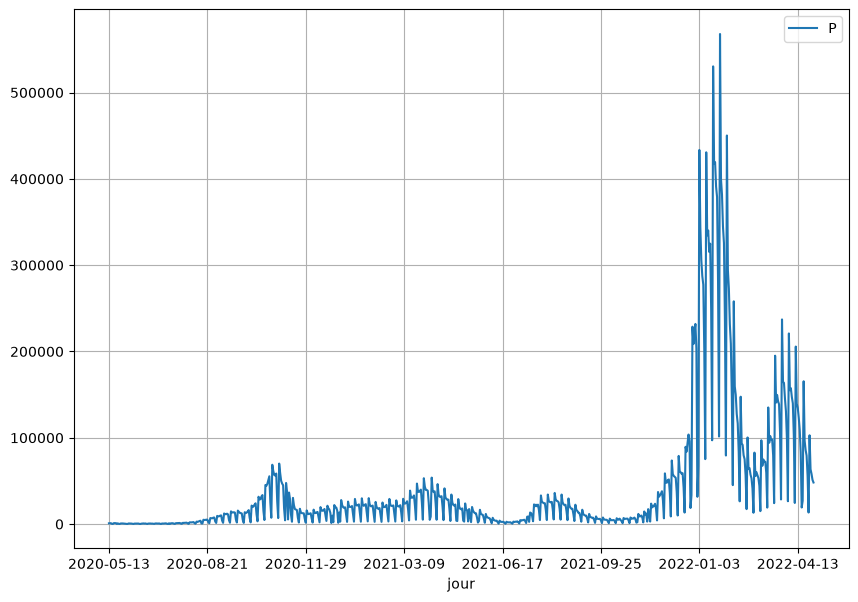

In [35]:
signal.plot(figsize=(10,7)).grid()

On peut regarder sur une zone plus restreinte, par exemple entre le 15 septembre et le 1er novembre 2020. Attention, les dates sont au format `yyyy/mm/dd` (année/mois/jour).

In [36]:
date_debut = '2020-09-15'
date_fin   = '2020-11-01'

signal_restreint = signal.loc[date_debut : date_fin]

On affiche le dataset...

In [37]:
signal_restreint

,P
jour,
2020-09-15,13529
2020-09-16,13450
2020-09-17,13732
2020-09-18,13285
2020-09-19,5203
2020-09-20,1805
2020-09-21,15641
2020-09-22,14223
2020-09-23,12993


On le visualise.

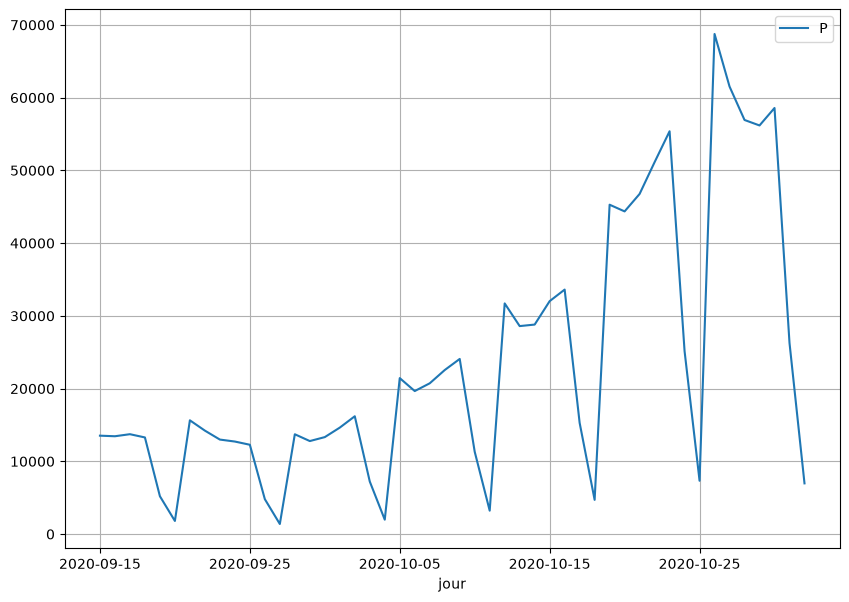

In [38]:
signal_restreint.plot(figsize=(10,7)).grid()

## À vous de jouer

**Question :** Quels jours de la semaine (lundi, mardi...) étions-nous les 19 et 20 septembre 2020 ? Les 24 et 25 octobre 2020 ?

19 Septembre = Jeudi
20 Septembre = Vendredi

24 Octobre = Jeudi
25 Octobre = Vendredi

**Question :** Qu'observe-t-on sur les signaux affichés ci-dessus (entier et restreint) ?

Periodique hebdomadaire? en hausse

-----

On convertit maintenant nos deux signaux (complet et restreint) en tableaux `numpy`, une librairie fondamentale pour le calcul numérique en Python.

In [39]:
s           = np.array(signal['P'])[:-1]
s_restreint = np.array(signal_restreint['P'])

**Question :** Calculer la transformée de Fourier du signal `s` en utilisant la fonction `rfft` fournie par le module `scipy.fft` (voir les imports en début de notebook). 

In [40]:
TFs = rfft(s)

-----

**Question :** Afficher le module de cette transformée de Fourier. 

*Indications :* Pour calculer le module d'un tableau `t` en Python, on fait `np.abs(t)`. Pour dessiner en Python (un `plot`), on déclare une figure `fig` et une zone de dessin `ax` en faisant `fig, ax = plt.subplots()`, et on utilise ensuite `ax.plot(ce-que-je-veux-afficher)`. On peut rajouter `ax.grid()` à la fin pour faire plus joli. 

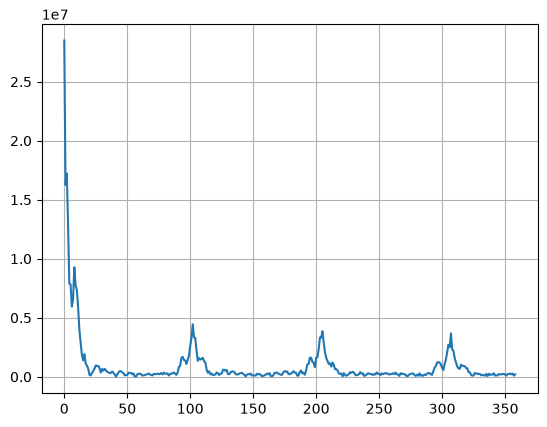

In [41]:
fig, ax = plt.subplots()
ax.plot(np.abs(TFs))
ax.grid()

**Question : commenter le résultat obtenu.**

_Indication :_ Ici, on calcule en fait ce qu'on appelle une _transformée de Fourier discrète_ (la deuxième partie du cours ; c'est essentiellement une TF "sur un ordinateur"). L'interprétation de l'axe des abscisses (fréquences) est la suivante : 
- Comme on calcule une TF sur un signal d'environ 700 jours, la fréquence d'indice $n$ en abscisse correspond à la présence d'une composante de fréquence $n/700$ (et donc de période $700/n$) dans le signal de départ. 

<span style="color: blue;">
On voit d'abord un énorme pic en 0 avec des basses fréquences très fortes. Ça correspond juste à la valeur moyenne du signal qui est toujours positive, et aux variations lentes sur toute la durée des 700 jours.
<br><br>
Ensuite il y a un pic très net vers $n \approx 100$. En faisant le calcul $700 / 100$, on retombe pile sur une période de 7 jours. Ça confirme direct le rythme hebdomadaire qu'on voyait avec la baisse des chiffres le week-end.
<br><br>
Enfin, on retrouve d'autres pics réguliers(? plus ou moins?) vers $n \approx 200$ et $300$. Ce sont simplement les harmoniques du pic de 7 jours, parce que le signal du week-end ne fait pas une belle sinusoïde mais des chutes plutôt abruptes.
</span>

**Question :** Calculer la transformée de Fourier inverse $\mathrm{TFI}(\mathrm{TF}(s))$ (avec la fonction `irfft`) de cette transformée de Fourier, et l'afficher. 

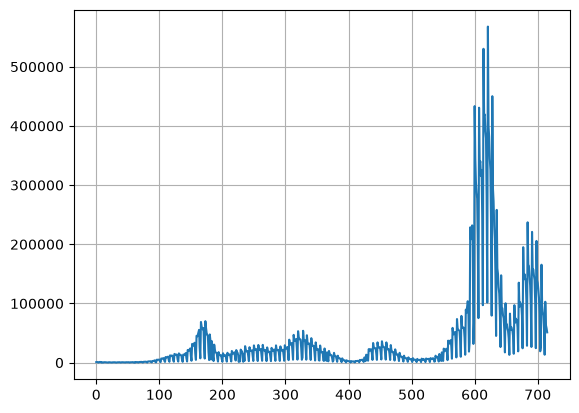

In [47]:
ITFs = irfft(TFs)
fig, bx = plt.subplots()
bx.plot(np.abs(ITFs))
bx.grid()

**Question :** Calculer numériquement la norme du vecteur $\|\mathrm{ITF}(\mathrm{TF}(s)) - s\|$. Qu'observe-t-on ?

*Indications :* On peut calculer la norme d'un vecteur `v` en utilisant `np.linalg.norm(v)`. La notation `...e-10` veut dire "à la puissance -10". 

In [49]:
norme = np.linalg.norm(irfft(TFs) - s)
norme

np.float64(1.2741222864198449e-09)

<span style="color: blue;">
La norme de la différence est extrêmement petite (de l'ordre de $10^{-9}$), ce qui est négligeable (?). Le signal reconstruit par ITF est donc identique au signal d'origine. L'opération est parfaitement réversible et il n'y a (presque?)aucune perte d'information.</span>

---

Pour mieux dégager la structure de ce signal, et donc voir la tendance globale, on va utiliser une convolution. On propose de regarder deux filtres: 

- Un filtre gaussien. 
- Un filtre « porte ». 

### Convolution par une Gaussienne

Avec `scipy`, la convolution avec un filtre gaussien se fait immédiatement grâce à la méthode `gaussian_filter1d(s , sigma)` où `s` désigne le signal d'entrée, et `sigma` la largeur de bande du filtre. 

**Question :** Compléter le code ci-dessous pour afficher : 
- Le signal filtré par une gaussienne de largeur de bande `sigma=0.1` sur le premier `ax`
- Le signal filtré par une gaussienne de largeur de bande `sigma=7`
- Le signal filtré par une gaussienne de largeur de bande `sigma=30`
- Le signal filtré par une gaussienne de largeur de bande `sigma=365`

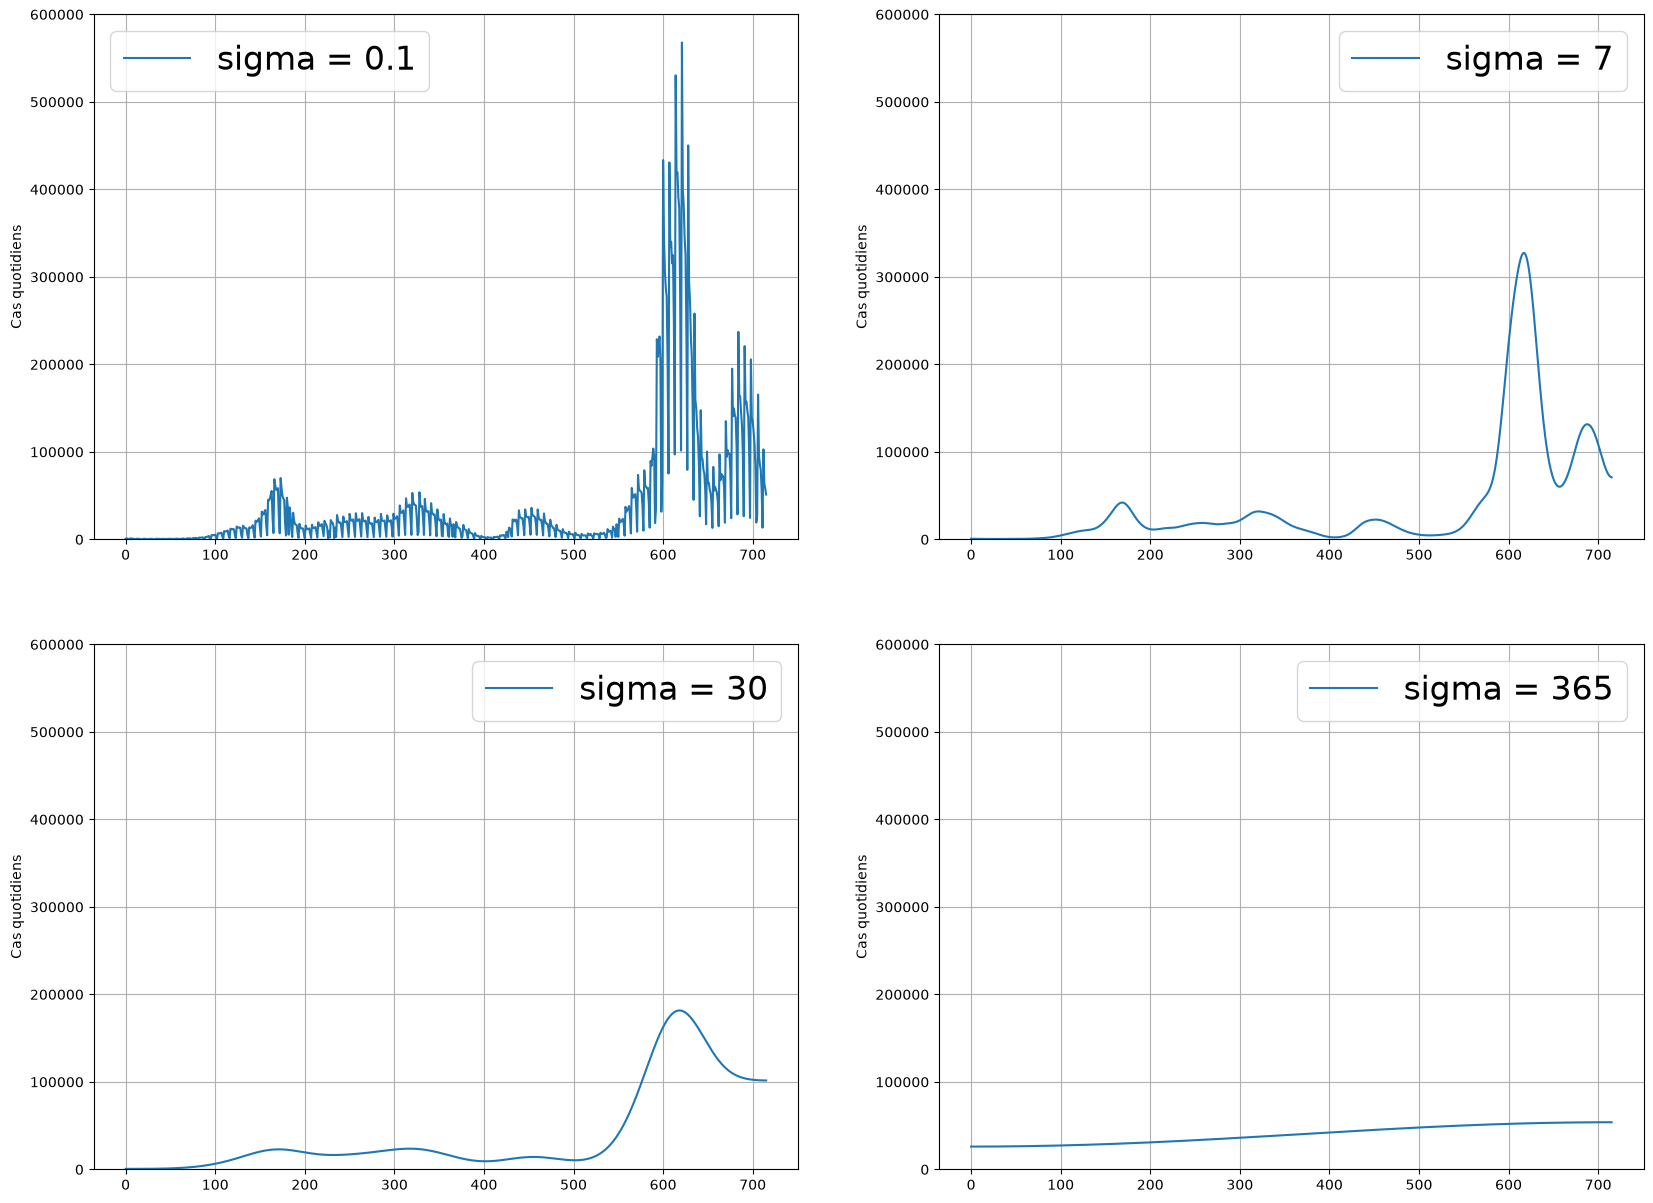

In [55]:
ymax = 600000  # pour avoir un bon affichage de l'axe des ordonnées.

fig, axs = plt.subplots(2, 2, figsize=(20, 15))
sigmas = [0.1, 7, 30, 365]

for sigma, ax in zip(sigmas, axs.flatten()):
    ax.plot(gaussian_filter1d(s, sigma), label='sigma = %s' %sigma)  # À COMPLÉTER
    ax.legend(fontsize=24)
    ax.set_ylim(0, ymax)
    ax.set_ylabel("Cas quotidiens")
    ax.grid()

----

**Question :** Commenter les quatre graphes obtenus ci-dessus. Quelle largeur de bande vous semble la plus pertinente ? Comment expliquer cela ?

 <span style="color: blue;">
Pour $\sigma = 0.1$, le filtre ne lisse quasiment rien : on conserve tout le bruit et les chutes hebdomadaires du week-end. À l'inverse, $\sigma = 30$ gomme trop de détails utiles, et $\sigma = 365$ sur-lisse totalement jusqu'à n'afficher qu'une ligne plate qui écrase toutes les vagues épidémiques.

La valeur la plus pertinente est donc $\sigma = 7$.

Cela s'explique directement par la périodicité de 7 jours mise en évidence plus haut : une fenêtre gaussienne de cet ordre permet d'éliminer l'effet week-end (les creux artificiels tous les 7 jours) tout en conservant fidèlement la dynamique réelle des différentes vagues et les pics d'infection.
</span>

----

**Question :** Calculer puis afficher le module de la transformée de Fourier de ces quatres signaux convolés. On pourra reprendre le code précédent pour faire la figure. 

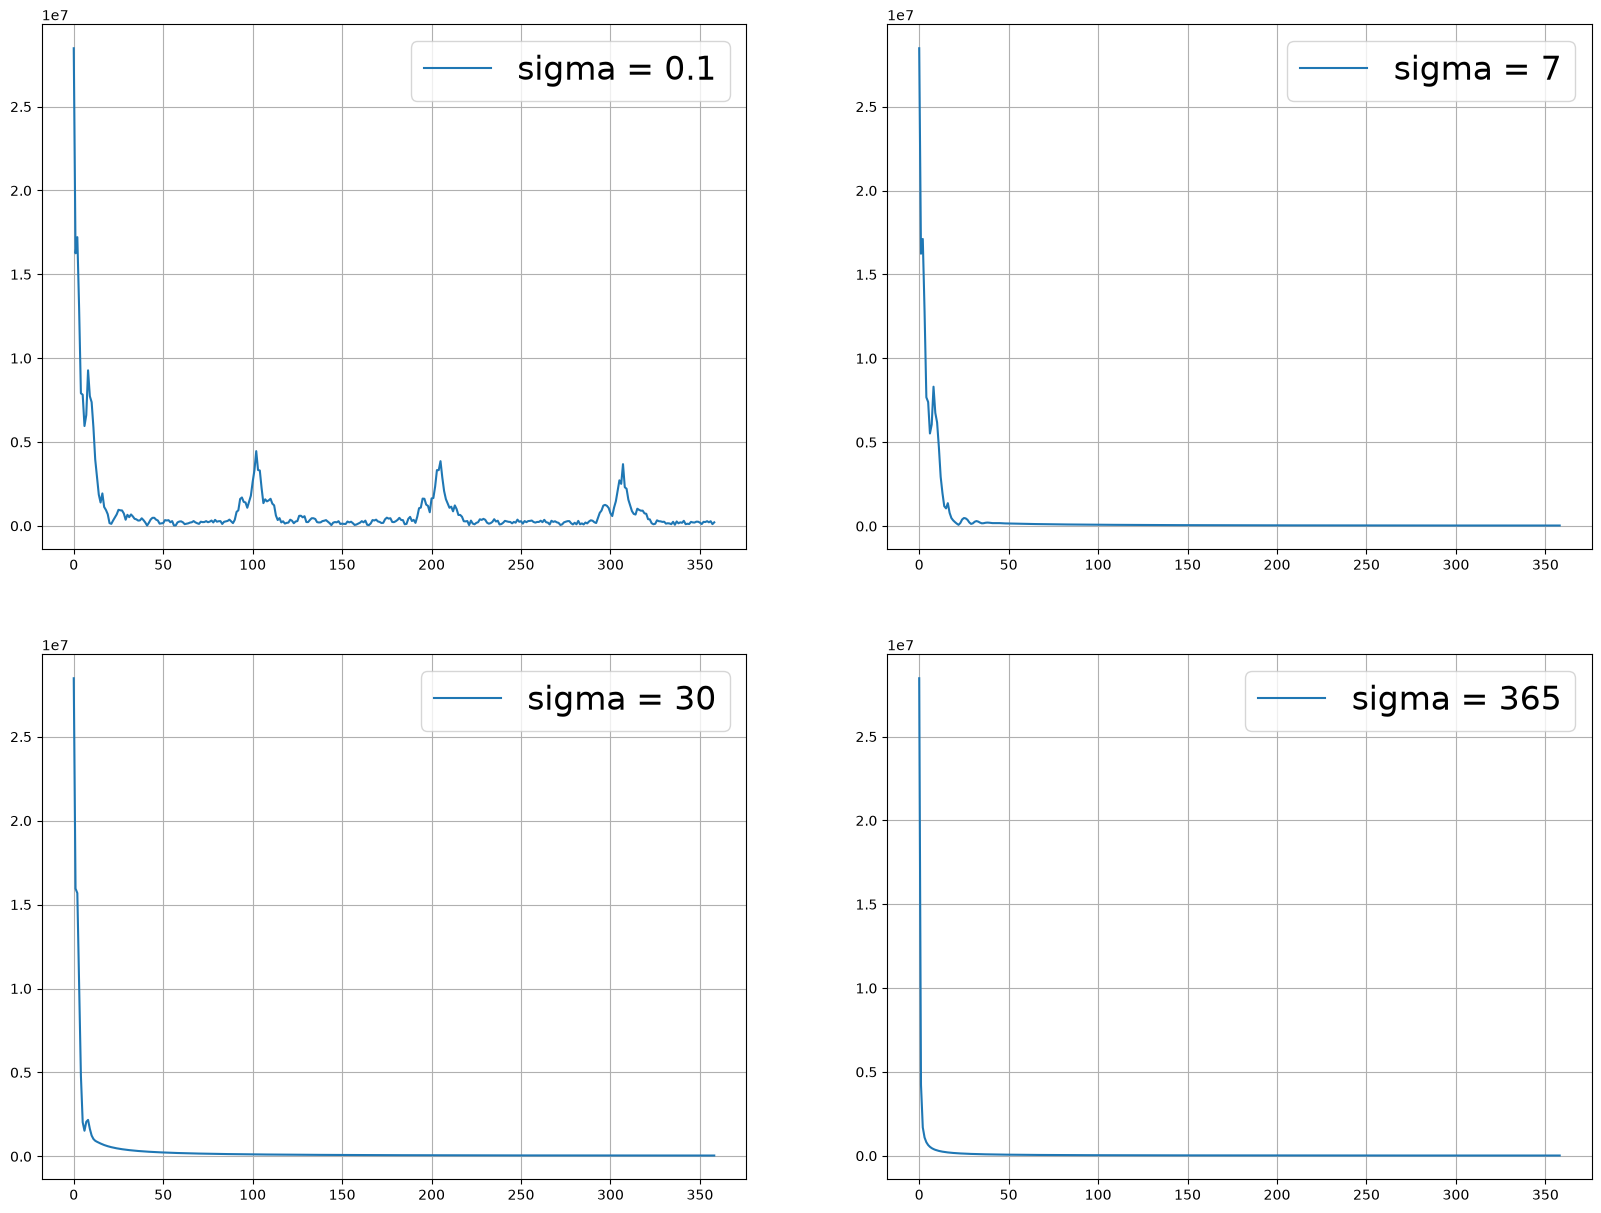

In [60]:
sigmas = [0.1, 7, 30, 365]

fig, axs = plt.subplots(2, 2, figsize=(20, 15))

for sigma, ax in zip(sigmas, axs.flatten()):
    ax.plot(np.abs(rfft(gaussian_filter1d(s, sigma))), label='sigma = %s' %sigma)   # À COMPLÉTER
    ax.legend(fontsize=24)
    ax.grid()

----

**Question :** Commenter les résultats obtenus.

<span style="color: blue;">
Le filtre gaussien agit directement comme un filtre passe-bas en fréquence. Plus $\sigma$ augmente, plus la bande passante se rétrécit et coupe les hautes fréquences.

Pour $\sigma = 0.1$, le spectre est quasi identique au signal d'origine : on retrouve le pic à $n \approx 100$ et toutes ses harmoniques ($n \approx 200, 300$). 

Dès $\sigma = 7$, ces pics sont totalement écrasés. Cela confirme mathématiquement que la composante hebdomadaire est éliminée tout en conservant les variations lentes. Pour $\sigma = 30$ et $\sigma = 365$, la coupure est trop agressive et ne laisse passer que la composante continue en 0.
</span>

### Avec un filtre porte

On va définir un filtre porte et calculer la colvolution avec notre signal pour différentes largueur de porte (on appelera encore la largeur `sigma`, pour être cohérent avec les notations pour le filtre gaussien). 

In [61]:
def porte(sigma, N):
    '''
    Cette fonction renvoie un filtre de longueur N, 
    et dont les sigma premières valeurs centrales 1 (et les autres valent 0)
    '''
    assert N > sigma, print("sigma (= %s) is too large compared to N (= %s)" % (sigma, N))
    return np.concatenate([np.zeros(int((N-sigma)/2)), 
                           np.ones(sigma), 
                           np.zeros(int((N-sigma)/2))])

Par exemple:

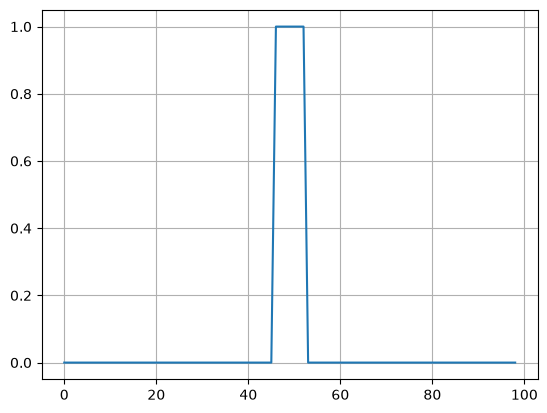

In [62]:
fig, ax = plt.subplots()
ax.plot(porte(7, 100))
ax.grid()

**Question :** Rappeler ce que représente la convolution par un signal porte. 

-- Écrire la réponse ici --

**Question :** Reprendre la partie précédente (afficher la convolution, puis la transformée de Fourier qui en résulte) en utilisant le filtre porte. Cette fois-ci, on calculera la convolution entre deux signaux `s` et `h` en utilisant la méthode `my_convolve(s,h)` fournie ci-dessous (construite à partir de la méthode `convolve` de `scipy`, mais avec des petits ajustements pour la rendre plus facile à utiliser).

On prendra pour longueur totale `N` du signal porte la taille du signal `s`, c'est-à-dire `N = s.shape[0]`. 

In [63]:
def my_convolve(s,h):
    return convolve(s,h, mode='same') / np.sum(h)

On commence par afficher les convolutions.

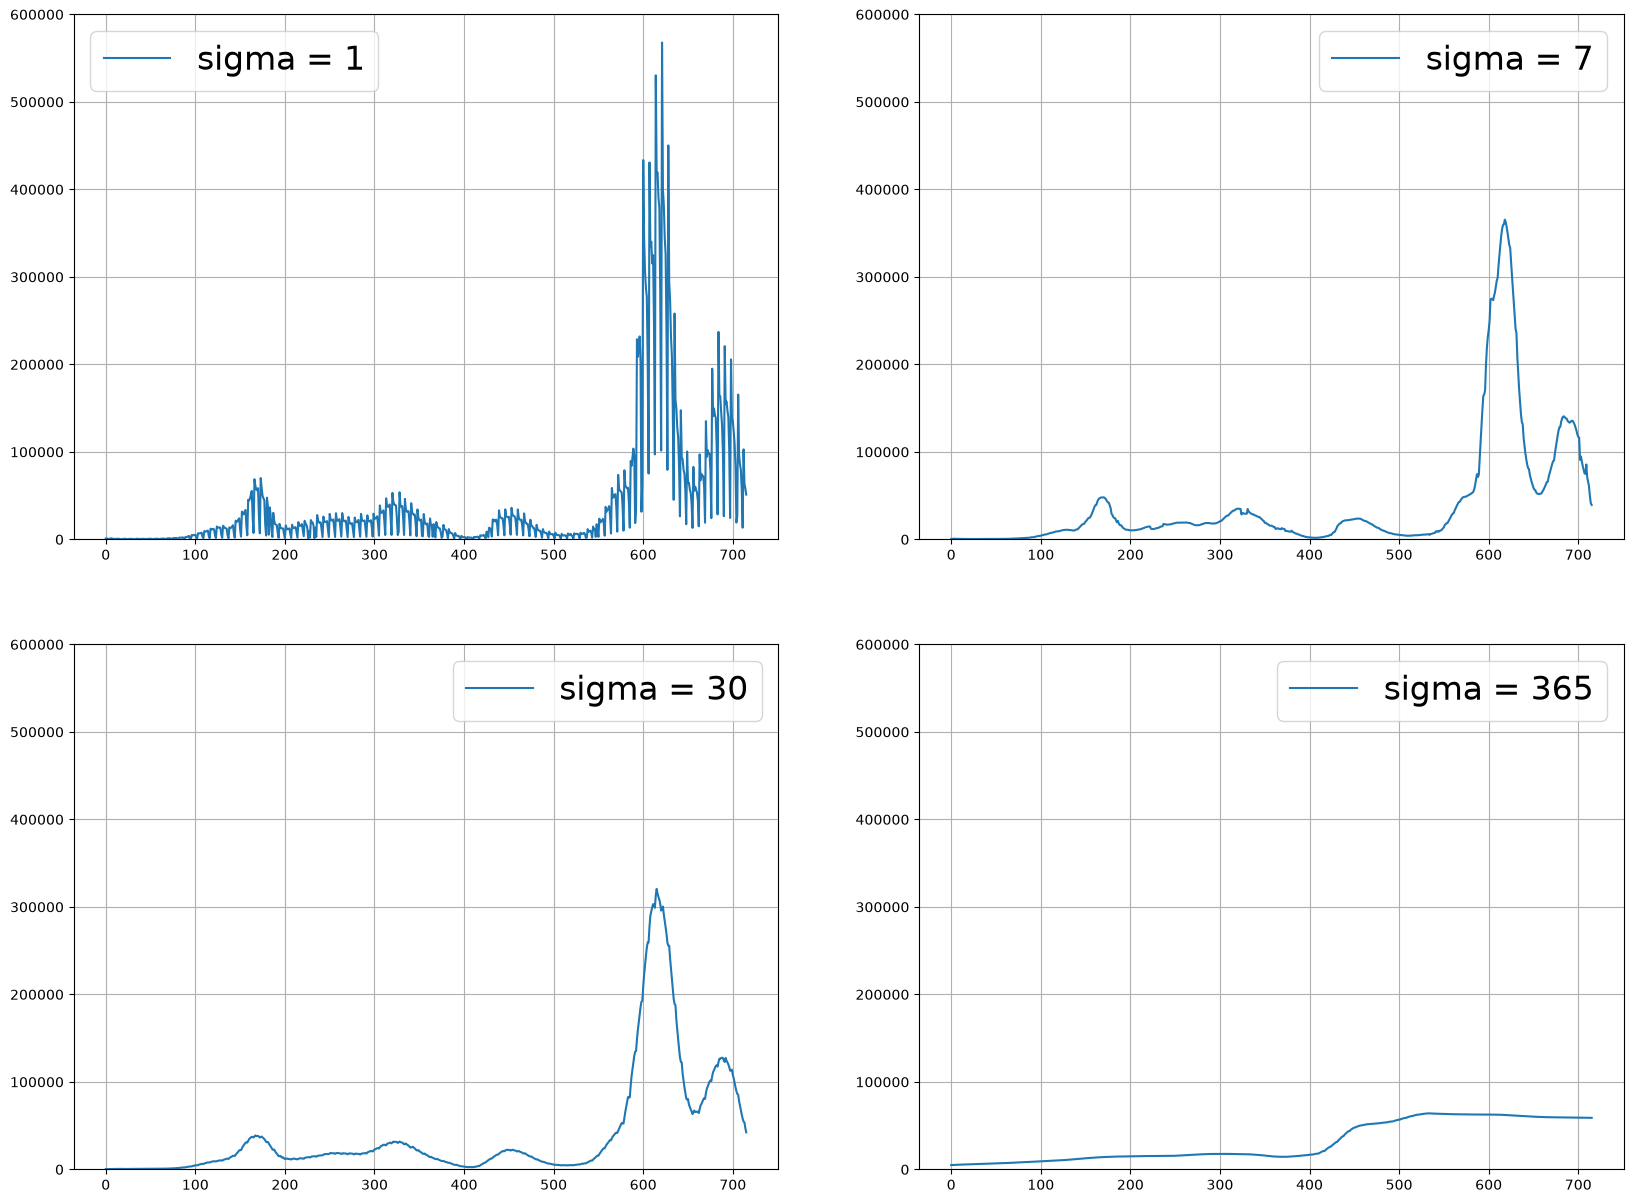

In [74]:
ymax = 600000

fig, axs = plt.subplots(2, 2, figsize=(20, 15))
sigmas = [1, 7, 30, 365]

N = s.shape[0]

for sigma, ax in zip(sigmas, axs.flatten()):
    h = np.ones(sigma)
    ax.plot(my_convolve(s, h), label='sigma = %s' % sigma)
    ax.legend(fontsize=24)
    ax.set_ylim(0, ymax)
    ax.grid()

Et maintenant les TF correspondantes.

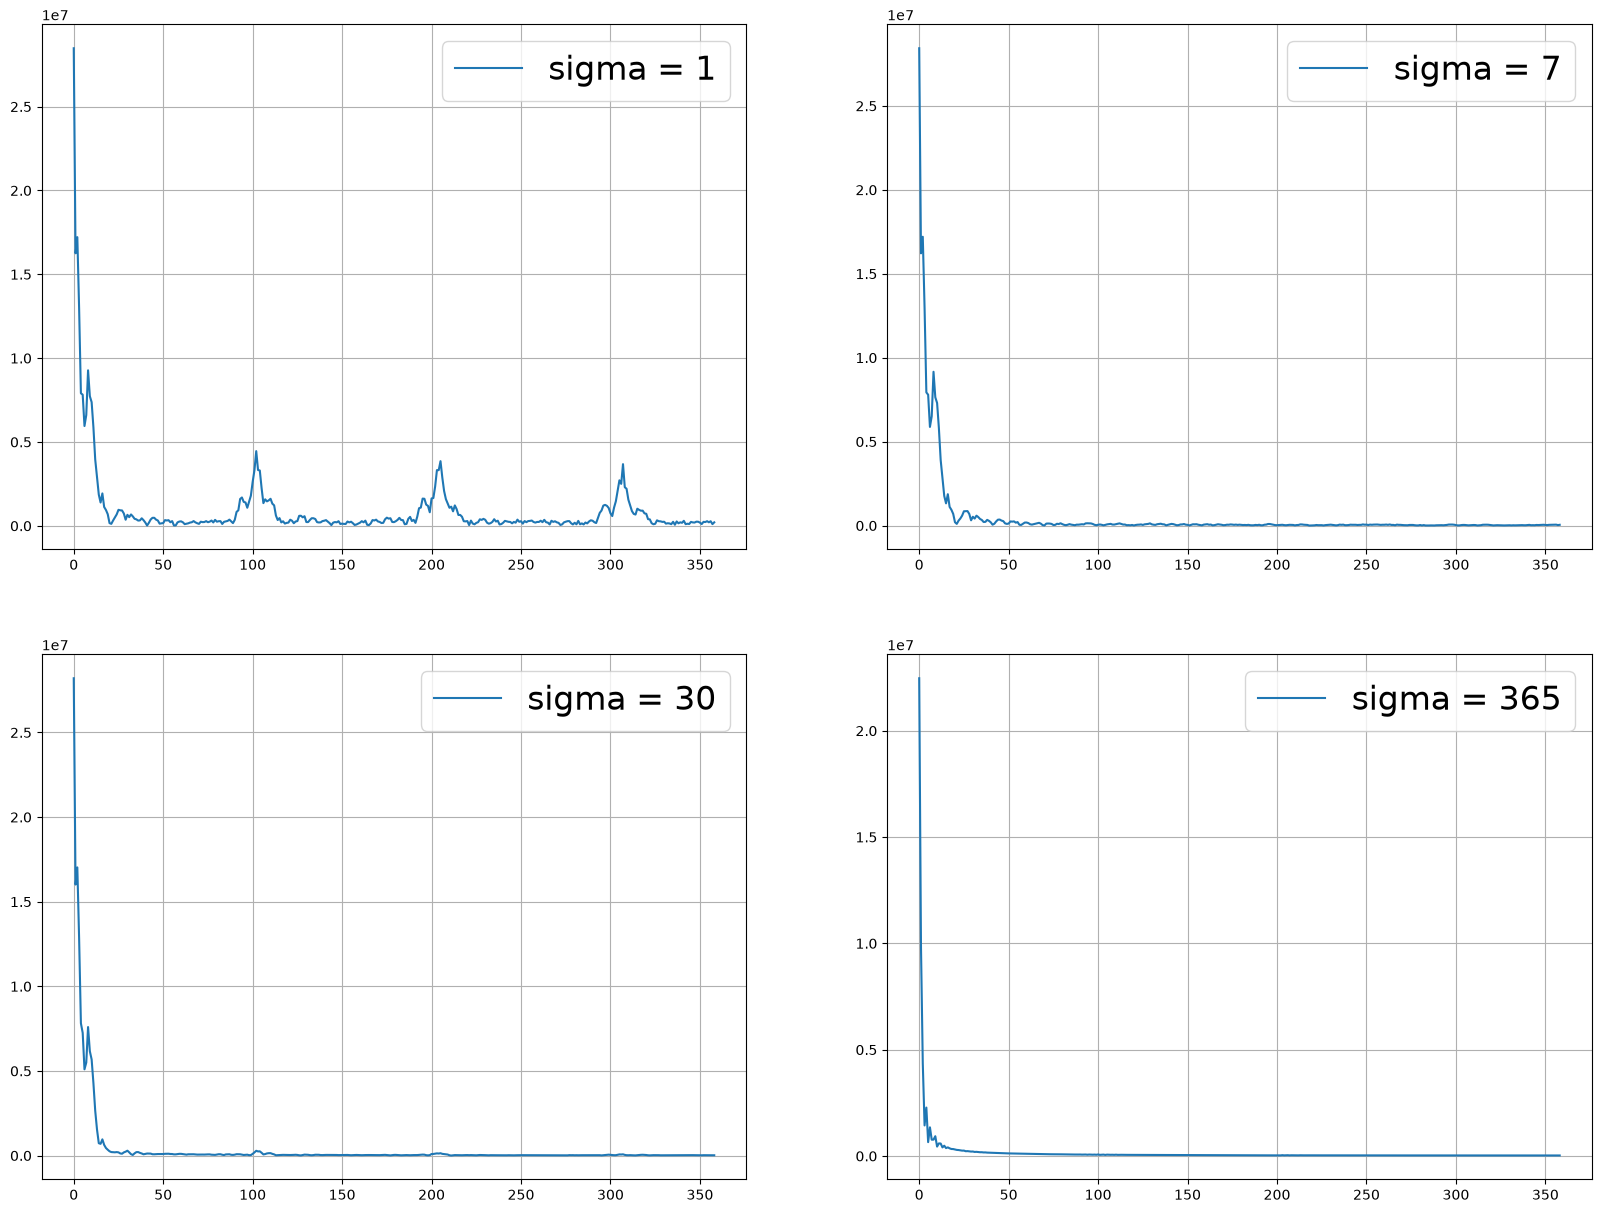

In [66]:
fig, axs = plt.subplots(2, 2, figsize=(20, 15))
sigmas = [1, 7, 30, 365]

N = s.shape[0]

for sigma, ax in zip(sigmas, axs.flatten()):
    h = np.ones(sigma)
    ax.plot(np.abs(rfft(my_convolve(s, h))), label='sigma = %s' % sigma)
    ax.legend(fontsize=24)
    ax.grid()

**Question :** Comparer les deux filtres et leur action sur le signal. 

_Indication :_ On pourra afficher les deux signaux sur une même figure. On peut également afficher ce qui se passe au niveau des hautes fréquences en faisant (par exemple) `X[200:]` (sélectionne toutes les valeurs à partir de `200` dans le tableau `X`). 

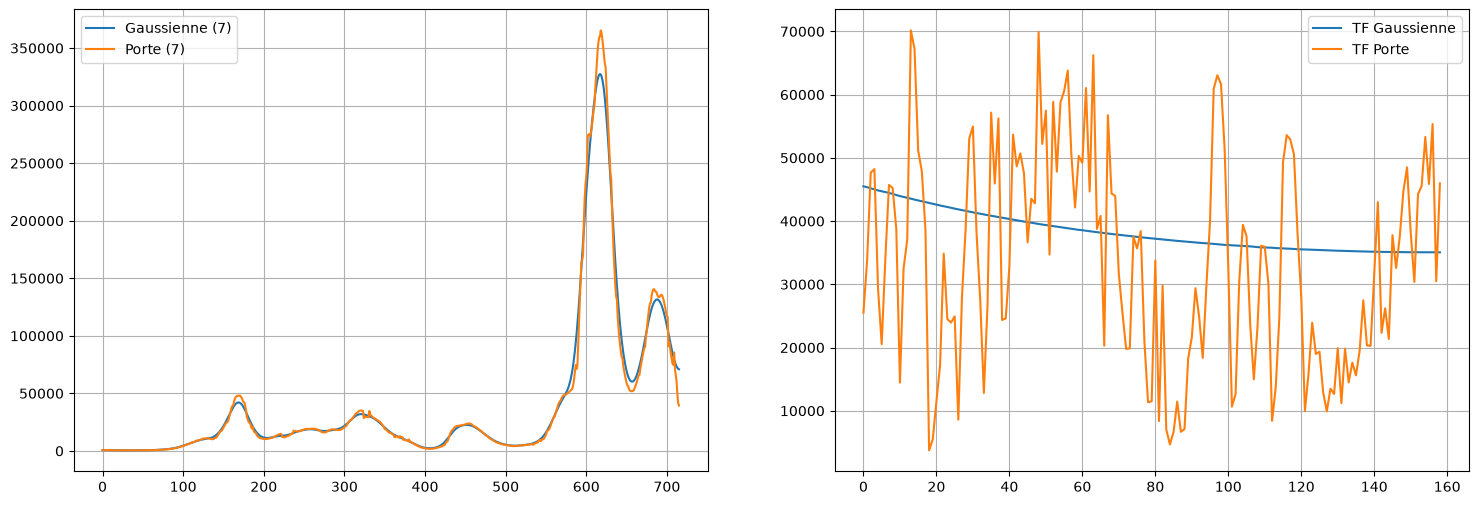

In [78]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Réutilisation deux filtres pour sigma = 7
sigma = 7
s_gauss = gaussian_filter1d(s, sigma)
s_porte = my_convolve(s, np.ones(sigma))

# Comparaison temporelle
ax1.plot(s_gauss, label='Gaussienne (7)')
ax1.plot(s_porte, label='Porte (7)')
ax1.legend()
ax1.grid()

# Comparaison des TF avec [200:]
TF_gauss = np.abs(rfft(s_gauss))
TF_porte = np.abs(rfft(s_porte))

ax2.plot(TF_gauss[200:], label='TF Gaussienne')
ax2.plot(TF_porte[200:], label='TF Porte')
ax2.legend()
ax2.grid()

<span style="color: blue;">
Côté temporel, les deux filtres lissent bien l'oscillation hebdomadaire, mais la porte donne un tracé un peu plus anguleux avec un léger décalage sur les extrema.

La différence saute aux yeux sur le zoom des hautes fréquences (indices $\ge 200$) :
- La gaussienne décroît de façon continue et très propre sans laisser passer de bruit résiduel.
- La porte (dont la TF est un sinus cardinal) présente d'énormes oscillations et rebonds dans les hautes fréquences.

La gaussienne est donc bien plus efficace pour filtrer sans réinjecter d'artefacts haute fréquence dans le signal.
</span>

### Détection de « vagues »

Pour faire simple, on va décréter qu'on a eu une « vague » de pandémie avec un pic au jour $t$ si on a plus de cas au jour $t$ qu'aux jours $t-1$ et $t+1$ (c'est vraiment très simplificateur). 

Pour déterminer les vagues dans un signal $s$ donné, on fournit la fonction suivante.

In [79]:
def vague_detecteur(s):
    """
    Détermine le nombre de "vague" qu'on peut observer dans un signal s. 
    
    Renvoie le nombre de vague détecté dans le signal s.
    """
    n = len(s)
    pics = []
    for t in range(1, n-1):
        if (s[t-1] < s[t]) & (s[t] > s[t+1]):
            pics.append(t)
    return len(pics)

**Question : Déterminer le nombre de vagues détectées dans le signal `s` brut. Commenter le résultat obtenu.**

In [80]:
nb_vagues_brut = vague_detecteur(s)
nb_vagues_brut

187

<span style="color: blue;">
On obtient un nombre de vagues très élevé (187), ce qui est absurde à l'échelle d'une pandémie.

La fonction se base uniquement sur une condition locale stricte ($s[t-1] < s[t] > s[t+1]$). Comme le signal brut n'est pas lissé, chaque petite fluctuation quotidienne et chaque remontée après le week-end est comptée à tort comme une "vague".
</span>

**Question : Déterminer le nombre de vagues détectées dans les versions convolées du signal `s` par une gaussienne et/ou une porte, pour différentes valeurs de `sigma`. Commenter les résultats obtenus.**

In [85]:
sigmas = [0.1, 7, 30, 365]

for sigma in sigmas:
    s_gauss = gaussian_filter1d(s, sigma)
    nb_gauss = vague_detecteur(s_gauss)
    
    if sigma >= 1:
        s_porte = my_convolve(s, np.ones(int(sigma)))
        nb_porte = vague_detecteur(s_porte)
    else:
        nb_porte = "xx"
        
    print(f"sigma = {sigma:5} | Gaussienne : {nb_gauss:2} vagues | Porte : {str(nb_porte):>2} vagues")

sigma =   0.1 | Gaussienne : 187 vagues | Porte : xx vagues
sigma =     7 | Gaussienne :  6 vagues | Porte : 50 vagues
sigma =    30 | Gaussienne :  4 vagues | Porte : 109 vagues
sigma =   365 | Gaussienne :  0 vagues | Porte : 15 vagues


--- Écrire votre commentaire ici ---

**Question (ouverte) : Dans les médias, la pandémie a essentiellement été présentée via la « moyenne 7 jours ». Selon vous, qu'est-ce qui justifie ce choix ?**

-- Écrivez votre commentaire ici --